Francis OMARA|MASTER OF SCIENCE IN DATA SCIENCE AND ANALYTICS|B35099|S25M19/022

In [ ]:
Project 1. Bank Marketing

Task: Develop and evaluate a model that predicts term-deposit subscription to support the selection of customers for a marketing campaign.

Problem Formulation

A Portuguese banking institution conducted telephone marketing campaigns to encourage customers to subscribe to term deposits.
A term deposit is an investment product where a customer deposits money with a bank for an agreed period and earns interest.
The bank wants to improve its marketing strategy by identifying customers who are more likely to subscribe to a term deposit.
Currently, the bank may spend considerable resources calling customers who eventually decline the offer. A predictive model could help the bank prioritise customers with a higher likelihood of subscribing.
The data science problem is therefore a binary classification problem.
Why binary classification?
Because the outcome variable has only two possible values:
Outcome	Meaning
Yes	Customer subscribed to a term deposit
No	Customer did not subscribe
The outcome y indicates whether a contacted customer subscribed to a term deposit (yes) or did not (no). The intended operational use is to rank customers before a campaign call so that limited calling resources are directed towards customers with a higher probability of subscribing.
The model will learn patterns from historical customer and campaign information and use those patterns to estimate the probability that a new customer will subscribe.


Importing Libraries

In [1]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    average_precision_score
)

sns.set_theme(style="whitegrid")

pd.set_option('display.max_columns', None)

Loading the dataset

In [2]:
bank_data = pd.read_csv(r"C:\Users\HP\Desktop\Mine\School\UCU\Y2\Semester One Y2\Data Mining Modeling & Analytics\CW1\dcs8307-advent-2026-assignment-1-material\bank-additional-full.csv" , sep=";")

In [3]:
bank_data.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [4]:
print("Number of observations:" , bank_data.shape[0])

print("Number of variables:" , bank_data.shape[1])

Number of observations: 41188
Number of variables: 21


In [5]:
bank_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [6]:
bank_data.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [7]:
bank_data.describe (include = "object")

,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,y
count,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188
unique,12,4,8,3,3,3,2,10,5,3,2
top,admin.,married,university.degree,no,yes,no,cellular,may,thu,nonexistent,no
freq,10422,24928,12168,32588,21576,33950,26144,13769,8623,35563,36548


Checking for missing values

In [8]:
missing_values = bank_data.isnull().sum()

print (missing_values)

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64


In [9]:
missing_percentage = (bank_data.isnull().sum() / len(bank_data)) * 100

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": missing_percentage
})

display(missing_summary)


,Missing Values,Percentage
age,0,0.0
job,0,0.0
marital,0,0.0
education,0,0.0
default,0,0.0
housing,0,0.0
loan,0,0.0
contact,0,0.0
month,0,0.0
day_of_week,0,0.0


In [10]:
print (bank_data ["y"].value_counts())

print (bank_data ["y"].value_counts(normalize = True) * 100)

y
no     36548
yes     4640
Name: count, dtype: int64
y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64


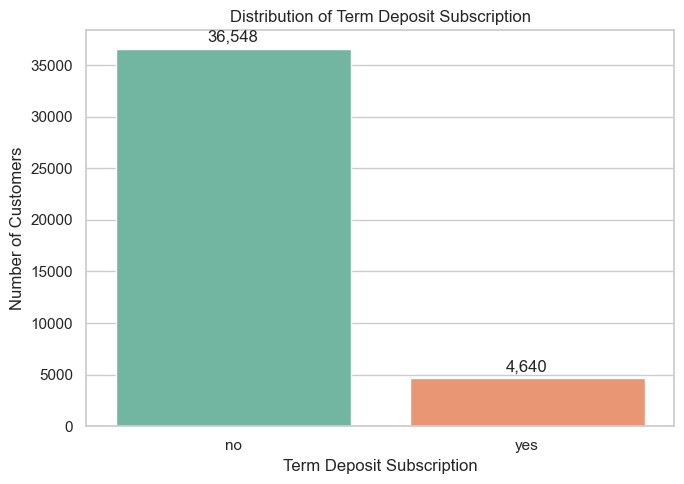

In [11]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(data=bank_data, x='y', hue='y',
                   palette='Set2', legend=False)

plt.title('Distribution of Term Deposit Subscription') 

plt.xlabel('Term Deposit Subscription')

plt.ylabel('Number of Customers')

for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', padding=3)

plt.tight_layout()

plt.show()

subscription by job category 

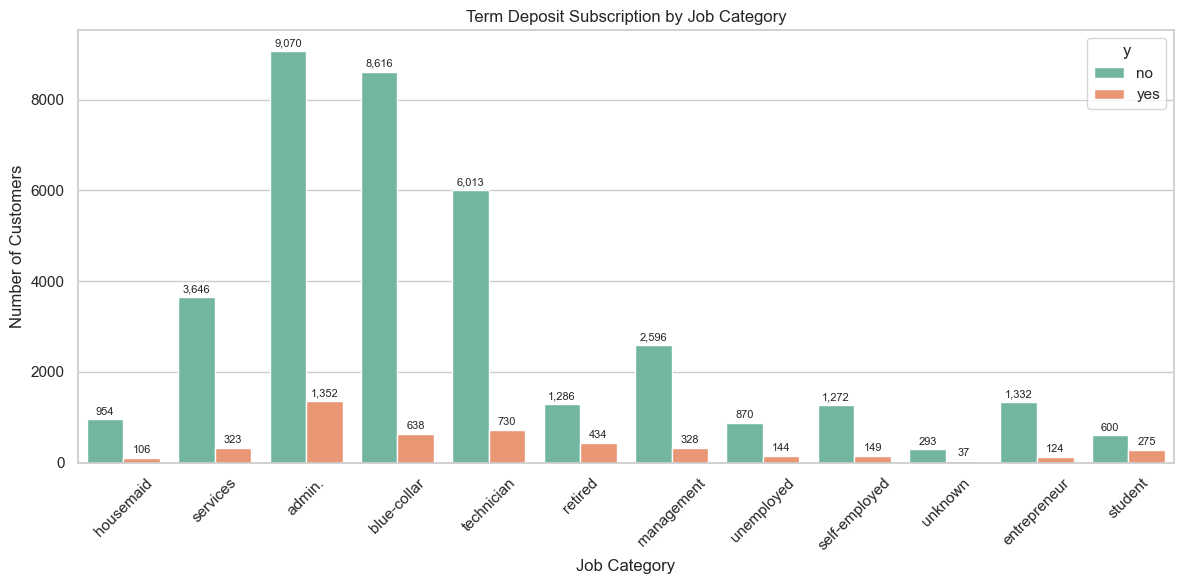

In [12]:
plt.figure(figsize=(12, 6))

ax = sns.countplot(data=bank_data, x='job', hue='y',
                   palette='Set2')

plt.title('Term Deposit Subscription by Job Category')

plt.xlabel('Job Category')

plt.ylabel('Number of Customers')

plt.xticks(rotation=45)

for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', padding=2, fontsize=8)

plt.tight_layout()

plt.show()

subscription by age

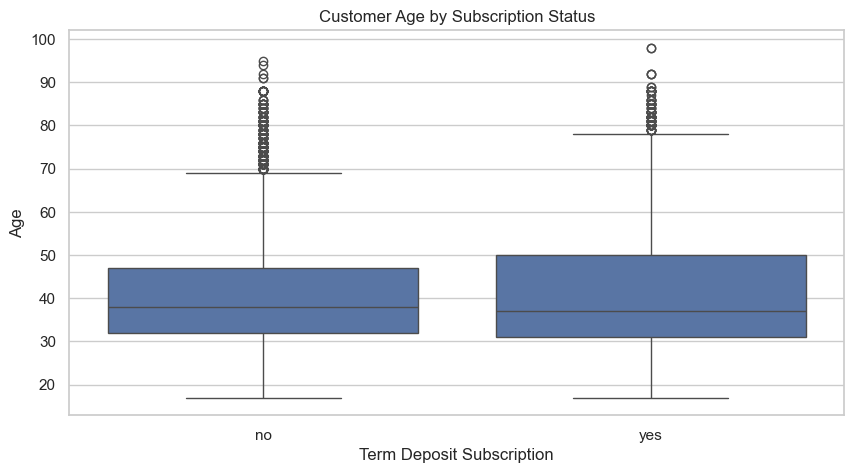

In [13]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=bank_data,
    x="y",
    y="age"
)

plt.title("Customer Age by Subscription Status")

plt.xlabel("Term Deposit Subscription")

plt.ylabel("Age")

plt.show()


Subscription by previous campaign outcome

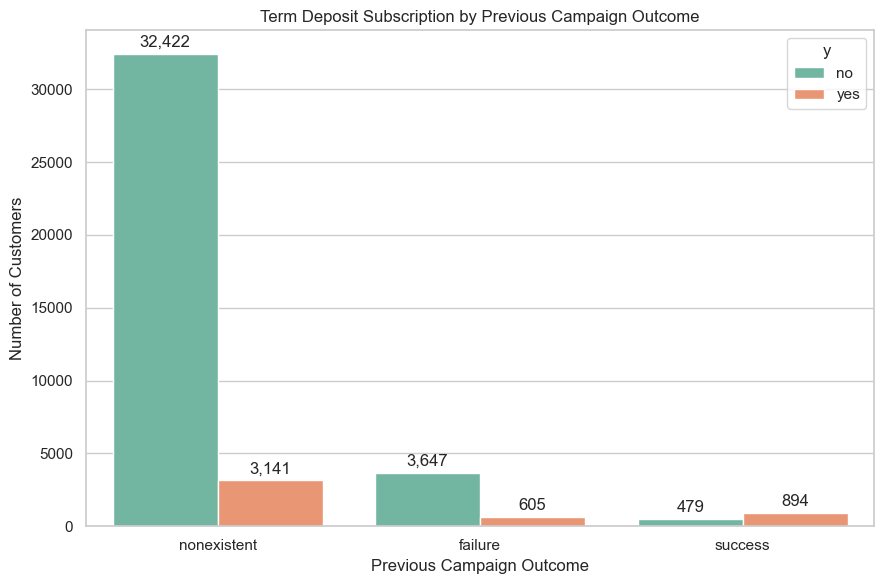

In [14]:
plt.figure(figsize=(9, 6))

ax = sns.countplot(data=bank_data, x='poutcome', hue='y',
                   palette='Set2')

plt.title('Term Deposit Subscription by Previous Campaign Outcome')

plt.xlabel('Previous Campaign Outcome')

plt.ylabel('Number of Customers')

for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', padding=3)

plt.tight_layout()

plt.show()

Data Preparation

In [15]:
# Separating predictors (X) and target variable (y)

X = bank_data.drop('y', axis=1)

y = bank_data['y']

print("Predictor dataset shape:", X.shape)

print("Target variable shape:", y.shape)

Predictor dataset shape: (41188, 20)
Target variable shape: (41188,)


In [16]:
# Removing duration to prevent data leakage

X = X.drop('duration', axis=1)

print("Predictor dataset shape after removing duration:", X.shape)

Predictor dataset shape after removing duration: (41188, 19)


In [17]:
# Creating an indicator for previous contact

X['previously_contacted'] = (X['pdays'] != 999).astype(int)

# Replacing 999 with NaN because the actual number of days is unknown
X['pdays'] = X['pdays'].replace(999, np.nan)

print(X[['pdays', 'previously_contacted']].head(10))

   pdays  previously_contacted
0    NaN                     0
1    NaN                     0
2    NaN                     0
3    NaN                     0
4    NaN                     0
5    NaN                     0
6    NaN                     0
7    NaN                     0
8    NaN                     0
9    NaN                     0


In [18]:
# Identifying categorical columns containing unknown values

categorical_columns = X.select_dtypes(include=['object']).columns

for column in categorical_columns:
    
    print(column, ":", (X[column] == 'unknown').sum())

job : 330
marital : 80
education : 1731
default : 8597
housing : 990
loan : 990
contact : 0
month : 0
day_of_week : 0
poutcome : 0


In [19]:
# Identifying numerical and categorical variables

numerical_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

categorical_features = X.select_dtypes(include=['object']).columns.tolist()

print("Numerical features:")

print(numerical_features)

print("\nCategorical features:")

print(categorical_features)

Numerical features:
['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted']

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


In [20]:
# Spliting the dataset into train and test

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training predictors:", X_train.shape)

print("Testing predictors:", X_test.shape)

print("\nTraining target distribution:")

print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")

print(y_test.value_counts(normalize=True) * 100)

Training predictors: (32950, 20)
Testing predictors: (8238, 20)

Training target distribution:
y
no     88.734446
yes    11.265554
Name: proportion, dtype: float64

Testing target distribution:
y
no     88.73513
yes    11.26487
Name: proportion, dtype: float64


Building the majority class classifier

In [21]:
from sklearn.dummy import DummyClassifier

# Creating the baseline model
baseline_model = DummyClassifier(strategy='most_frequent')

# Training the baseline model
baseline_model.fit(X_train, y_train)

# Making predictions on the test dataset
baseline_predictions = baseline_model.predict(X_test)

print("First 20 baseline predictions:")

print(baseline_predictions[:20])

First 20 baseline predictions:
['no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no'
 'no' 'no' 'no' 'no' 'no' 'no']


In [22]:
# Evaluation metrics
baseline_accuracy = accuracy_score(y_test, baseline_predictions)

baseline_precision = precision_score(
    y_test, baseline_predictions,
    pos_label='yes', zero_division=0
)

baseline_recall = recall_score(
    y_test, baseline_predictions,
    pos_label='yes', zero_division=0
)

baseline_f1 = f1_score(
    y_test, baseline_predictions,
    pos_label='yes', zero_division=0
)

# Display results
print("BASELINE MODEL PERFORMANCE")

print("---------------------------")

print(f"Accuracy:  {baseline_accuracy:.4f}")

print(f"Precision: {baseline_precision:.4f}")

print(f"Recall:    {baseline_recall:.4f}")

print(f"F1-score:  {baseline_f1:.4f}")

BASELINE MODEL PERFORMANCE
---------------------------
Accuracy:  0.8874
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000


In [23]:
#Classififcation report

print("BASELINE CLASSIFICATION REPORT")

print(classification_report(
    y_test,
    baseline_predictions,
    labels=['no', 'yes'],
    zero_division=0
))

BASELINE CLASSIFICATION REPORT
              precision    recall  f1-score   support

          no       0.89      1.00      0.94      7310
         yes       0.00      0.00      0.00       928

    accuracy                           0.89      8238
   macro avg       0.44      0.50      0.47      8238
weighted avg       0.79      0.89      0.83      8238



Confusion Matrix

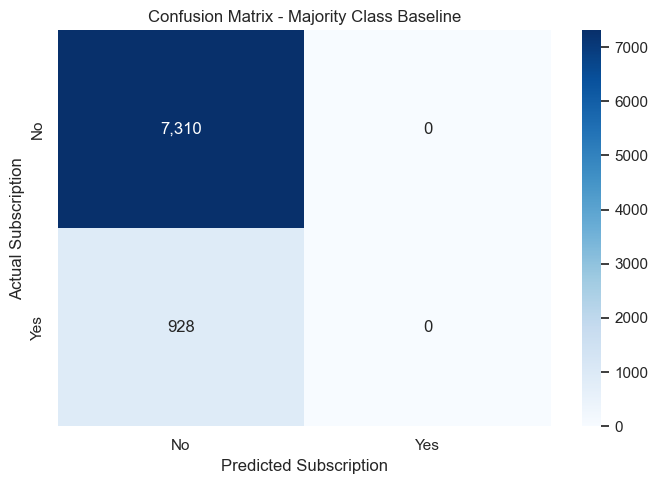

In [24]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    baseline_predictions,
    labels=['no', 'yes']
)

plt.figure(figsize=(7, 5))

ax = sns.heatmap(
    cm,
    annot=True,
    fmt=',',
    cmap='Blues',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.title('Confusion Matrix - Majority Class Baseline')

plt.xlabel('Predicted Subscription')

plt.ylabel('Actual Subscription')

plt.tight_layout()

plt.show()

Building the three classification models (Logistic, random forest and HistGradientBoosting)

Identifying numerical and categorical variables

In [25]:
numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical features:", numerical_features)

print("\nCategorical features:", categorical_features)

Numerical features: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted']

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


Preprocessing Pipeline

In [26]:
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

# Combining numerical and categorical preprocessing
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Preprocessing pipeline successfully created.")

Preprocessing pipeline successfully created.


Model 1: Logistic Regression

In [27]:
from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

Model 2: Random Forest

In [28]:
random_forest_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    ))
])

Model 3: HistGradientBoosting

In [29]:
gradient_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.08,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    ))
])

Training the three models

In [30]:
# Training Logistic Regression
logistic_model.fit(X_train, y_train)

# Training Random Forest
random_forest_model.fit(X_train, y_train)

# Training HistGradientBoosting
gradient_model.fit(X_train, y_train)

print("All three models have been successfully trained.")

All three models have been successfully trained.


In [31]:
# Generating predictions
logistic_predictions = logistic_model.predict(X_test)

random_forest_predictions = random_forest_model.predict(X_test)

gradient_predictions = gradient_model.predict(X_test)

print("Predictions successfully generated.")

Predictions successfully generated.


In [32]:
# Probability of subscribing (yes)

logistic_probabilities = logistic_model.predict_proba(X_test)[
    :, list(logistic_model.classes_).index('yes')
]

random_forest_probabilities = random_forest_model.predict_proba(X_test)[
    :, list(random_forest_model.classes_).index('yes')
]

gradient_probabilities = gradient_model.predict_proba(X_test)[
    :, list(gradient_model.classes_).index('yes')
]

print("Predicted subscription probabilities generated.")

Predicted subscription probabilities generated.


Evaluating Model performance 

In [33]:
# Converting actual outcomes into binary values
y_test_binary = (y_test == 'yes').astype(int)

def evaluate_model(model_name, predictions, probabilities):

    return {
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(
            y_test, predictions, pos_label='yes', zero_division=0
        ),
        'Recall': recall_score(
            y_test, predictions, pos_label='yes', zero_division=0
        ),
        'F1-score': f1_score(
            y_test, predictions, pos_label='yes', zero_division=0
        ),
        'ROC-AUC': roc_auc_score(
            y_test_binary, probabilities
        ),
        'Average Precision': average_precision_score(
            y_test_binary, probabilities
        )
    }


# Evaluating the three models
results = []

results.append(evaluate_model(
    'Logistic Regression',
    logistic_predictions,
    logistic_probabilities
))

results.append(evaluate_model(
    'Random Forest',
    random_forest_predictions,
    random_forest_probabilities
))

results.append(evaluate_model(
    'HistGradientBoosting',
    gradient_predictions,
    gradient_probabilities
))


# Creating performance comparison table
results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
display(results_df.round(4))

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,Logistic Regression,0.9008,0.6881,0.2188,0.3320,0.8009,0.4656
1,Random Forest,0.9020,0.6516,0.2802,0.3919,0.7999,0.4803
2,HistGradientBoosting,0.9029,0.6818,0.2586,0.3750,0.8143,0.4932


Visualising the model performance comparison

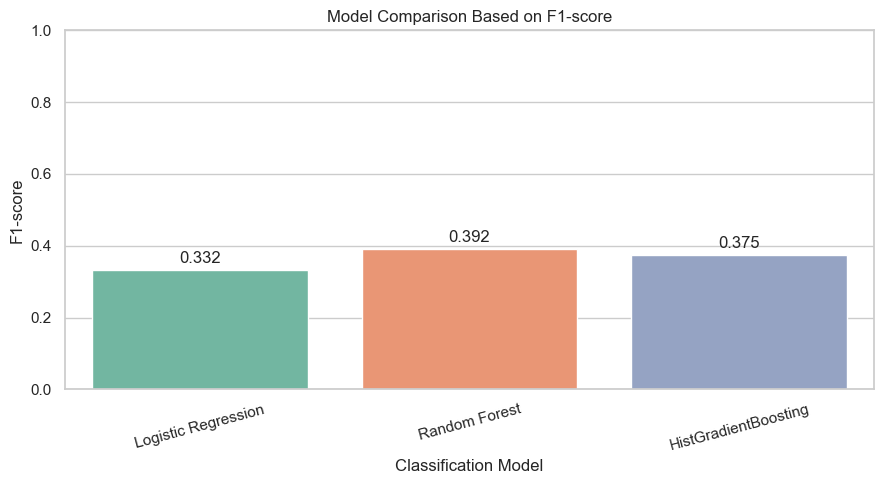

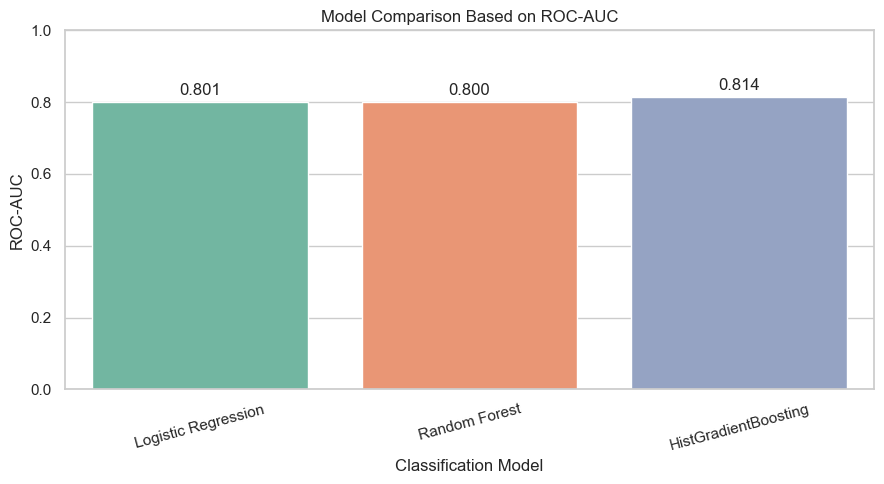

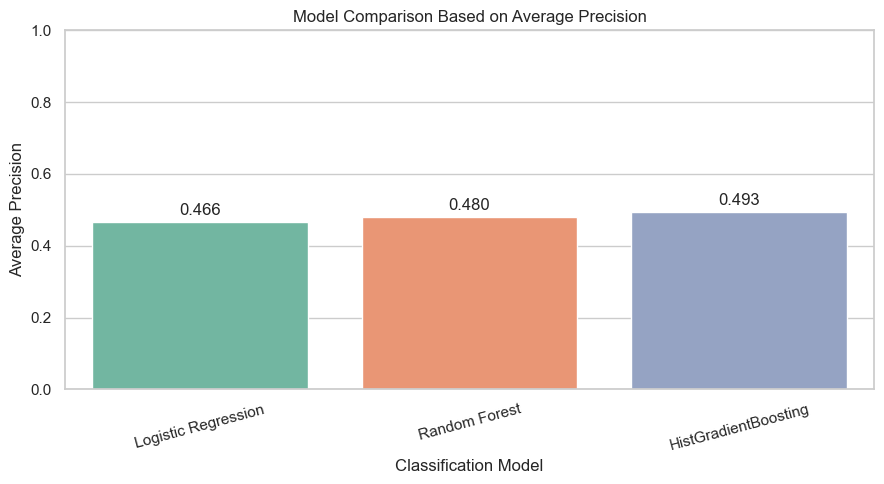

In [36]:
metrics_to_plot = ['F1-score', 'ROC-AUC', 'Average Precision']

for metric in metrics_to_plot:

    plt.figure(figsize=(9, 5))

    ax = sns.barplot(
        data=results_df,
        x='Model',
        y=metric,
        hue='Model',
        palette='Set2',
        legend=False
    )

    plt.title(f'Model Comparison Based on {metric}')
    plt.xlabel('Classification Model')
    plt.ylabel(metric)
    plt.ylim(0, 1)

    # Add data labels
    for container in ax.containers:
        ax.bar_label(container, fmt='%.3f', padding=3)

    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

Ranking the models

In [35]:
# Ranking models using ROC-AUC and Average Precision

results_df['Overall Rank Score'] = (
    results_df['ROC-AUC'] + results_df['Average Precision']
) / 2

ranked_models = results_df.sort_values(
    by='Overall Rank Score',
    ascending=False
).reset_index(drop=True)

ranked_models.insert(
    0,
    'Rank',
    range(1, len(ranked_models) + 1)
)

display(ranked_models.round(4))

,Rank,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision,Overall Rank Score
0,1,HistGradientBoosting,0.9029,0.6818,0.2586,0.3750,0.8143,0.4932,0.6537
1,2,Random Forest,0.9020,0.6516,0.2802,0.3919,0.7999,0.4803,0.6401
2,3,Logistic Regression,0.9008,0.6881,0.2188,0.3320,0.8009,0.4656,0.6333


Creating a validation dataset

In [37]:
# Spliting the existing training data into fitting and validation sets

X_train_fit, X_val, y_train_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Model fitting data:", X_train_fit.shape)
print("Validation data:", X_val.shape)

Model fitting data: (26360, 20)
Validation data: (6590, 20)


In [38]:
#Training the selected HistGradientBoosting model

# Creating a fresh HistGradientBoosting pipeline

hgb_threshold_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.08,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    ))
])

# Fitting the model
hgb_threshold_model.fit(X_train_fit, y_train_fit)

print("HistGradientBoosting model fitted successfully.")

HistGradientBoosting model fitted successfully.


In [39]:
# Obtaining predicted probabilities 

hgb_val_probabilities = hgb_threshold_model.predict_proba(X_val)[
    :, list(hgb_threshold_model.classes_).index('yes')
]

print("First 10 predicted subscription probabilities:")
print(hgb_val_probabilities[:10])

First 10 predicted subscription probabilities:
[0.08284282 0.04464282 0.08683622 0.12138627 0.32776053 0.04794006
 0.04797091 0.37980186 0.05283855 0.03271822]


In [40]:
#Evaluating different classification thresholds

# Defining the thresholds to evaluate

thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

threshold_results = []

for threshold in thresholds:

    # Convert probabilities into predictions
    threshold_predictions = np.where(
        hgb_val_probabilities >= threshold,
        'yes',
        'no'
    )

    # Calculating performance metrics
    precision = precision_score(
        y_val, threshold_predictions,
        pos_label='yes', zero_division=0
    )

    recall = recall_score(
        y_val, threshold_predictions,
        pos_label='yes', zero_division=0
    )

    f1 = f1_score(
        y_val, threshold_predictions,
        pos_label='yes', zero_division=0
    )

    accuracy = accuracy_score(y_val, threshold_predictions)

    threshold_results.append({
        'Threshold': threshold,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-score': f1
    })

# Creating comparison table
threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Accuracy,Precision,Recall,F1-score
0,0.10,0.8155,0.3381,0.6671,0.4488
1,0.15,0.8602,0.4177,0.6119,0.4964
2,0.20,0.8744,0.4547,0.5822,0.5106
3,0.25,0.8825,0.4813,0.5553,0.5156
4,0.30,0.8877,0.5013,0.5040,0.5027
5,0.35,0.8964,0.5582,0.3814,0.4532
6,0.40,0.8995,0.6070,0.3059,0.4068
7,0.45,0.8998,0.6273,0.2722,0.3797
8,0.50,0.9003,0.6641,0.2318,0.3437


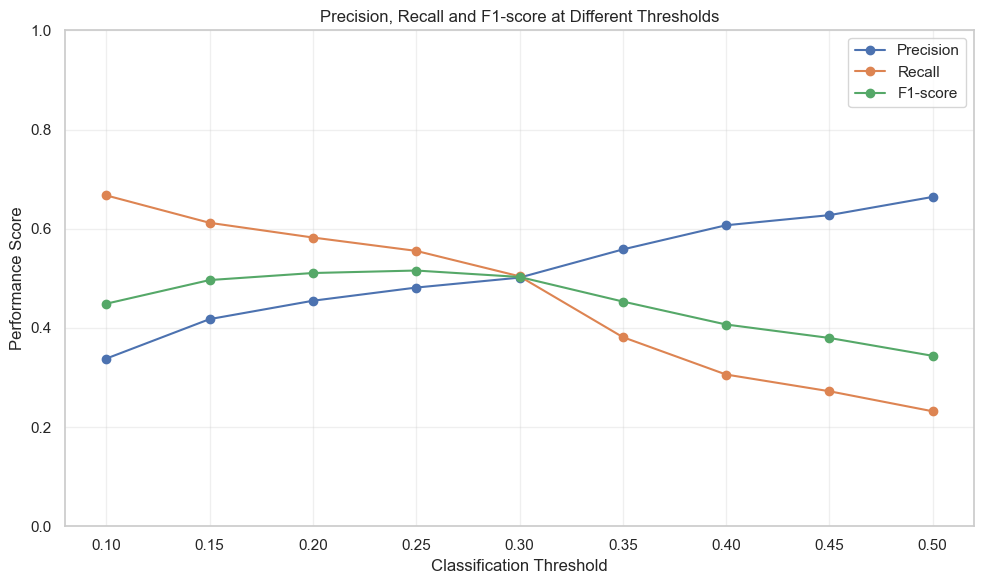

In [41]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Precision'],
    marker='o',
    label='Precision'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Recall'],
    marker='o',
    label='Recall'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['F1-score'],
    marker='o',
    label='F1-score'
)

plt.title('Precision, Recall and F1-score at Different Thresholds')
plt.xlabel('Classification Threshold')
plt.ylabel('Performance Score')
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [42]:
# Identifying the threshold with the highest F1-score

best_threshold_row = threshold_df.loc[
    threshold_df['F1-score'].idxmax()
]

print("Best threshold based on F1-score:")
print(best_threshold_row)

Best threshold based on F1-score:
Threshold    0.250000
Accuracy     0.882549
Precision    0.481308
Recall       0.555256
F1-score     0.515645
Name: 3, dtype: float64


Retraining the model using the full training dataset (using the same HistGradientBoosting configuration but trained it on all the original training observations.)

In [43]:
# Creating the final HistGradientBoosting model

final_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.08,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    ))
])

# Train using the full training dataset
final_model.fit(X_train, y_train)

print("Final model trained successfully.")

Final model trained successfully.


In [44]:
# Predict probabilities on the test dataset

test_probabilities = final_model.predict_proba(X_test)[
    :, list(final_model.classes_).index('yes')
]

print("Test probabilities generated successfully.")

Test probabilities generated successfully.


In [45]:
# Applying recommended threshold of of 0.25

# Setting the recommended threshold
recommended_threshold = 0.25

# Convert probabilities into subscription predictions
final_predictions = np.where(
    test_probabilities >= recommended_threshold,
    'yes',
    'no'
)

print("Final predictions generated using threshold:", recommended_threshold)

Final predictions generated using threshold: 0.25


In [46]:
# EValuating the final model

final_accuracy = accuracy_score(y_test, final_predictions)

final_precision = precision_score(
    y_test, final_predictions,
    pos_label='yes', zero_division=0
)

final_recall = recall_score(
    y_test, final_predictions,
    pos_label='yes', zero_division=0
)

final_f1 = f1_score(
    y_test, final_predictions,
    pos_label='yes', zero_division=0
)

final_roc_auc = roc_auc_score(
    (y_test == 'yes').astype(int),
    test_probabilities
)

final_average_precision = average_precision_score(
    (y_test == 'yes').astype(int),
    test_probabilities
)

# Display results
final_results = pd.DataFrame([{
    'Model': 'HistGradientBoosting',
    'Threshold': recommended_threshold,
    'Accuracy': final_accuracy,
    'Precision': final_precision,
    'Recall': final_recall,
    'F1-score': final_f1,
    'ROC-AUC': final_roc_auc,
    'Average Precision': final_average_precision
}])

display(final_results.round(4))

,Model,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,HistGradientBoosting,0.25,0.8821,0.4804,0.569,0.521,0.8143,0.4932


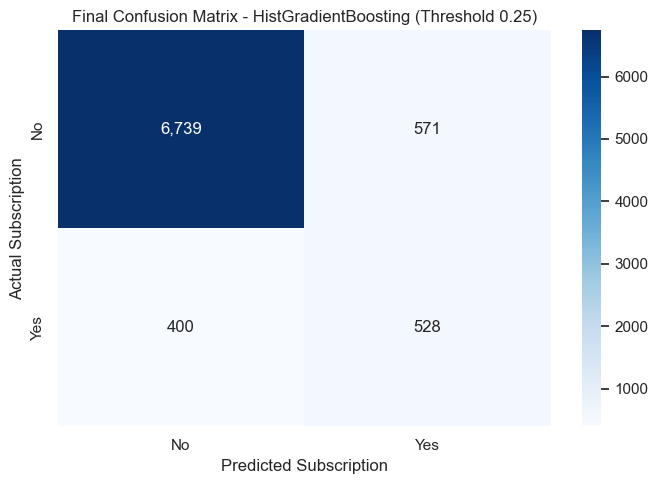

In [47]:
# Generating the confusion matrix

final_cm = confusion_matrix(
    y_test,
    final_predictions,
    labels=['no', 'yes']
)

# Plot confusion matrix
plt.figure(figsize=(7, 5))

ax = sns.heatmap(
    final_cm,
    annot=True,
    fmt=',',
    cmap='Blues',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.title('Final Confusion Matrix - HistGradientBoosting (Threshold 0.25)')
plt.xlabel('Predicted Subscription')
plt.ylabel('Actual Subscription')

plt.tight_layout()
plt.show()

In [49]:
# Generating the classification report

print("FINAL CLASSIFICATION REPORT")

print(classification_report(
    y_test,
    final_predictions,
    labels=['no', 'yes'],
    zero_division=0
))

FINAL CLASSIFICATION REPORT
              precision    recall  f1-score   support

          no       0.94      0.92      0.93      7310
         yes       0.48      0.57      0.52       928

    accuracy                           0.88      8238
   macro avg       0.71      0.75      0.73      8238
weighted avg       0.89      0.88      0.89      8238



Explore and write a short report on the data and carryout necessary data preparation, with justification. Establish a majority-class baseline.

Introduction

The objective of this project was to develop a classification model that predicts whether a bank customer will subscribe to a term deposit following a direct marketing campaign. The analysis used the Bank Marketing dataset, which contains information on customers' demographic characteristics, financial circumstances, marketing campaign interactions, previous campaign outcomes and prevailing economic conditions.
The target variable y, which represents whether a customer subscribed to a term deposit (yes) or did not subscribe (no). The predictive model is intended to support the bank in identifying customers who are more likely to subscribe, thereby improving the effectiveness of marketing campaigns, optimising resource allocation and reducing unnecessary customer contacts.
The first stage of the analysis involved exploring the dataset, assessing its structure and quality, preparing the variables for machine-learning modelling and establishing a majority-class baseline against which more advanced classification models could subsequently be evaluated.

The use of predictive analytics in bank telemarketing has been investigated by Moro, Cortez and Rita (2014), who developed data mining models to predict the success of marketing calls for selling long-term bank deposits. Their study demonstrated the value of using customer characteristics and socio-economic information to identify potential subscribers and support more effective marketing campaign targeting. This provides a relevant foundation for the current analysis, which uses customer demographic, campaign-related and economic variables to predict term-deposit subscription. The study also highlights the importance of selecting predictors that are available before a marketing call is made, ensuring that the model can be used for practical customer targeting.

Dataset Description and Exploration
    
Overview of the dataset
    
The analysis used the bank-additional-full.csv dataset, which contains 41,188 observations and 21 variables. The dataset consisted of 20 potential predictor variables and one target variable.
The predictor variables capture different dimensions of customer characteristics, marketing campaign activities and economic conditions that may be associated with term-deposit subscription.
The variables are categorised into the following groups:
Variable category	Variables	Description
Customer demographics	Age, job, marital, education	Describe customers' demographic and socio-economic characteristics.
Financial characteristics	Default, housing, loan	Indicate customers' credit default status and existing housing or personal loans.
Campaign and contact information	Contact, month, day_of_week, campaign, pdays, previous, poutcome	Describe communication channels, campaign timing, number of contacts and previous campaign experiences.
Economic indicators	emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed	Capture broader economic conditions that may influence customers' financial decisions.
Target variable	y	Indicates whether a customer subscribed to a term deposit.
The dataset contains both numerical and categorical variables, making it suitable for supervised classification using different machine-learning algorithms.

Data structure and quality assessment
                                                                         
Initial data exploration was conducted to understand the dataset's dimensions, variable types, descriptive statistics and completeness. The inspection confirmed that the dataset contains 41,188 observations across 21 variables.
The dataset includes numerical variables such as age, campaign, previous and economic indicators, as well as categorical variables such as job, marital status, education, contact type and previous campaign outcome.
The initial missing-value assessment did not identify conventional null values in the dataset. However, several categorical variables contained the value unknown, indicating that some customer information was unavailable or not recorded.
These values were retained as a distinct category rather than treated as conventional missing observations. This approach avoids unnecessary loss of observations and allows the models to learn whether the absence of recorded information is associated with subscription behaviour.
Another important observation concerned the pdays variable. A value of 999 represents customers who had not previously been contacted during an earlier marketing campaign. This is a special coding convention rather than an actual number of days and therefore required appropriate treatment during data preparation.

Distribution of the target variable
    
Exploration of the target variable revealed a substantial imbalance between customers who subscribed and those who did not.
The dataset contains approximately:

Subscription outcome	Number of observations	Percentage
    
No – did not subscribe	36,548	88.7%
Yes – subscribed	4,640	11.3%
Total	41,188	100%
The findings indicate that approximately 88.7% of customers did not subscribe, compared with only 11.3% who subscribed.
This imbalance is important because a classification model could achieve relatively high accuracy simply by predicting the majority class without identifying any actual subscribers. Consequently, accuracy alone would not provide a sufficient assessment of model performance. Additional metrics, particularly precision, recall and F1-score for the subscriber class, are necessary to evaluate the model's practical usefulness.

Exploration of relationships between customer characteristics and subscription
    
Exploratory visualisations were generated to investigate how subscription outcomes varied across selected customer and campaign characteristics.
The analysis examined subscription patterns by age group, job category, education level, marital status, contact type and previous campaign outcome.
Age was grouped into meaningful intervals to facilitate comparison of subscription patterns across different age categories. Count plots were used to compare the numbers of subscribers and non-subscribers within each category, while subscription-rate plots were used to examine the proportion of customers subscribing within each age group.
The distinction between customer counts and subscription rates is important. A category may have a higher number of subscribers simply because it contains more customers overall. Subscription rates therefore provide a more meaningful basis for comparing the relative likelihood of subscription across categories.
The exploratory analysis provides an initial understanding of potential relationships between customer characteristics and subscription behaviour. However, these relationships are descriptive and do not establish that any particular customer characteristic causes a customer to subscribe.

Data Preparation and Preprocessing

Data preparation was undertaken to ensure that the dataset was appropriate for machine-learning modelling and that the predictors reflected information available at the time the bank would make customer-selection decisions.

Separation of predictors and target variable
    
The target variable y was separated from the remaining variables to create the predictor matrix (X) and target vector (y).
The target variable represents the subscription outcome, while the predictor variables contain the customer, campaign and economic information used by the models to estimate the likelihood of subscription.
This separation is necessary because supervised machine-learning algorithms learn relationships between predictor variables and a known target outcome.

Removal of the duration variable to prevent data leakage
    
The variable duration, which represents the length of a telephone call in seconds, was excluded from the predictor variables.
This decision was based on the intended application of the model. The objective is to identify potential subscribers before the bank initiates marketing calls. Call duration is only known after a customer has been contacted and therefore would not be available when the bank is selecting customers for its campaign.
Including this variable would introduce data leakage because it contains information generated during the marketing interaction. Its inclusion could artificially improve predictive performance while producing a model that would not be practical for pre-campaign customer selection.
Consequently, duration was removed to ensure that the model relies only on information available before the marketing call.

Treatment of the pdays variable

The pdays variable required special treatment because the value 999 represents customers who had not previously been contacted during an earlier marketing campaign.
Treating 999 as a genuine numerical value could mislead the model into interpreting these customers as having experienced an exceptionally long period since their previous contact.
To address this issue, a binary variable named previously_contacted was created. It identifies whether a customer had previously been contacted.
Customers with pdays = 999 were assigned a value of zero for the new indicator, while customers with other values were assigned one. The original 999 values were then replaced with missing values to allow appropriate numerical imputation.
This approach preserves the information about previous contact while avoiding the incorrect interpretation of the sentinel value as a genuine numerical measurement.

Treatment of unknown categorical values
    
Categorical variables containing the value unknown were retained as a separate category.
Deleting observations with unknown values could unnecessarily reduce the dataset size and introduce bias, particularly if missing information is systematically associated with particular customer groups.
Retaining these observations allows the machine-learning models to incorporate the available information while treating unknown responses as a distinct category during encoding.

Numerical and categorical variable transformation
                                                                                                        
The dataset contains both numerical and categorical predictors, which require different preprocessing procedures before modelling.
Numerical variables were processed using median imputation and standardisation. Median imputation was selected because it is less sensitive to extreme values than mean imputation. Standardisation was applied to place numerical variables on comparable scales, which is particularly important for algorithms such as Logistic Regression that are sensitive to differences in feature magnitudes.
Categorical variables were processed using one-hot encoding. This transformation converts categorical values into numerical binary indicators that can be interpreted by machine-learning algorithms.
The handle_unknown='ignore' option was included to ensure that the model can process categories encountered in validation or test data that were not present during training.
A preprocessing pipeline combining numerical and categorical transformations was established to ensure consistency in data preparation across the different classification models.

Splitting the dataset into training and testing sets
                  
The prepared dataset was divided into training and testing subsets using an 80:20 split.
The training dataset was used to develop the machine-learning models, while the testing dataset was reserved for evaluating their predictive performance on observations not used during model training.
Stratified sampling was applied using the target variable to preserve approximately the same proportion of subscribers and non-subscribers in both subsets.
This was particularly important because of the class imbalance in the original dataset. Without stratification, the training and testing subsets could contain substantially different proportions of subscribers, potentially affecting model development and evaluation.
An 80:20 split provides sufficient observations for model training while retaining an independent dataset for performance assessment.

Establishing a Majority-Class Baseline
                                                                                                          
Baseline model selection
                                                                                                          
A majority-class baseline was established using Scikit-learn's DummyClassifier with the most_frequent strategy.
The majority-class classifier predicts the most frequently occurring target category for every observation, without considering the predictor variables.
Since approximately 88.7% of the customers in the dataset did not subscribe to term deposits, the baseline model predicts that every customer will belong to the non-subscriber (no) category.
The purpose of establishing this baseline is to provide a simple benchmark against which the performance of more advanced machine-learning models can be assessed.

Baseline model performance
                                                                                     
The majority-class classifier was trained using the training dataset and evaluated on the independent test dataset.
The following performance metrics were obtained:

Evaluation metric	Baseline performance

Accuracy	0.8874
Precision (yes)	0.0000
Recall (yes)	0.0000
F1-score (yes)	0.0000
The model achieved an accuracy of approximately 88.74%. However, this relatively high accuracy is misleading because the classifier predicts every customer as a non-subscriber.
Consequently, it fails to identify any actual subscribers, resulting in zero precision, recall and F1-score for the yes class.

The high baseline accuracy should be interpreted cautiously because the dataset is highly imbalanced, with non-subscribers accounting for approximately 88.7% of observations and subscribers representing only 11.3%. He and Garcia (2009) explain that class imbalance presents a significant challenge in machine learning because standard classification algorithms and evaluation measures can favour the majority class, potentially resulting in poor identification of minority-class observations. This is evident in the current analysis, where the majority-class classifier achieves relatively high accuracy by predicting every customer as a non-subscriber, yet fails to identify any actual subscribers. Consequently, accuracy alone is insufficient for assessing model effectiveness, and additional metrics such as precision, recall and F1-score are necessary.

Interpretation of baseline results
    
The baseline results demonstrate the limitations of relying exclusively on accuracy when evaluating classification models trained on imbalanced datasets.
Although the classifier correctly identifies a substantial proportion of non-subscribers, it completely fails to identify customers who would subscribe to a term deposit.
From a business perspective, such a model would be unsuitable for supporting the bank's marketing campaign because it would not generate any meaningful list of potential subscribers.
The baseline therefore establishes an important benchmark for subsequent modelling. More advanced classification algorithms should demonstrate improved performance, particularly in identifying actual subscribers while maintaining an acceptable level of precision.

Conclusion
                                                                                     
The exploratory analysis established that the Bank Marketing dataset contains 41,188 observations and 21 variables, with a binary target variable indicating whether customers subscribed to term deposits. The target distribution is substantially imbalanced, with approximately 88.7% of customers classified as non-subscribers and 11.3% as subscribers.
Data preparation addressed several important issues, including the removal of call duration to prevent data leakage, appropriate treatment of the pdays = 999 sentinel value, retention of unknown categorical values, numerical standardisation and categorical encoding. The dataset was subsequently divided into training and testing subsets using stratified sampling to preserve the original class distribution.
The majority-class baseline achieved approximately 88.74% accuracy but recorded zero precision, recall and F1-score for the subscriber class. This demonstrates that a high accuracy score does not necessarily indicate a useful classification model, particularly where the outcome variable is imbalanced.
The findings establish the need for more advanced classification approaches capable of identifying potential subscribers more effectively. Subsequent modelling will therefore focus on improving subscriber identification and evaluating the trade-off between contacting customers who may not subscribe and missing customers who are likely to subscribe.




Select and rank at-most 3 approaches and/or suitable for predicting the term-deposit subscription? Justify your selection and ranking with supporting evidence.

Introduction

The objective of this task was to identify suitable machine learning models for predicting whether a bank customer will subscribe to a term deposit following a marketing campaign. Since the target variable (y) has two possible outcomes, yes or no, this is a binary classification problem.
Three machine learning approaches were selected and evaluated: Logistic Regression, Random Forest, and HistGradientBoosting. These models were chosen because they offer different strengths in classification, can capture different types of relationships in the data, and provide a useful basis for comparing predictive performance.

Selected Models and Justification

1. HistGradientBoosting Classifier

HistGradientBoosting is an ensemble learning algorithm that builds decision trees sequentially, with each new tree attempting to correct errors made by previous trees. It can capture complex, non-linear relationships and interactions between customer characteristics and subscription behaviour.
It was selected because customer decisions to subscribe to a term deposit may depend on combinations of factors such as age, employment status, previous campaign outcomes, contact method and economic conditions. Gradient boosting can capture these relationships more effectively than a simple linear model.

2. Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines predictions from multiple decision trees. Each tree is trained using a different sample of the training data and a random subset of features. The combined predictions generally improve model stability and reduce the risk of overfitting associated with individual decision trees.
It was selected because it can identify complex relationships, handle a mixture of numerical and categorical predictors after preprocessing, and capture interactions between variables without requiring extensive assumptions about their relationships with the target variable.

3. Logistic Regression

Logistic Regression is a statistical classification algorithm that estimates the probability of an observation belonging to a particular class. It models the relationship between predictor variables and the probability of a customer subscribing to a term deposit.
It was selected because it is relatively simple, computationally efficient and interpretable. It also provides a useful benchmark against which the performance of more complex ensemble models can be compared. Its probabilistic predictions make it suitable for evaluating different classification thresholds.

The selection of multiple classification algorithms is consistent with the approach adopted by Moro et al. (2014), who compared different data mining techniques to identify the most suitable model for predicting bank telemarketing success. The authors demonstrated that predictive performance varies across modelling approaches and that empirical evaluation is necessary when selecting a model for a particular business problem. More recent work by Du (2025) also reports the potential of gradient boosting approaches in predicting term-deposit subscriptions using the Bank Marketing dataset. These studies support the evaluation of both traditional statistical approaches, such as Logistic Regression, and ensemble methods, such as Random Forest and HistGradientBoosting, rather than relying on a single algorithm.
    
Model Performance Comparison
The three models were trained and evaluated using the same training and test datasets. Their performance was assessed using accuracy, precision, recall, F1-score, ROC-AUC and Average Precision.

The results are presented below.

Performance metric	Logistic Regression	Random Forest	HistGradientBoosting
Accuracy	0.9008	0.9020	0.9029
Precision	0.6881	0.6516	0.6818
Recall	0.2188	0.2802	0.2586
F1-score	0.3320	0.3919	0.3750
ROC-AUC	0.8009	0.7999	0.8143
Average Precision	0.4656	0.4803	0.4932

Note: The metrics above represent performance at the default classification threshold of 0.50.

Ranking of the Selected Models

Based on the evaluation results, the models are ranked as follows:
Rank 1: HistGradientBoosting Classifier
HistGradientBoosting is ranked first because it achieved the highest ROC-AUC of 0.8143 and Average Precision of 0.4932. These metrics indicate that it performed best in distinguishing between customers who subscribed and those who did not, and in ranking potential subscribers ahead of non-subscribers.
It also achieved the highest accuracy of 90.29%, although the difference between the three models was relatively small. Its ability to capture non-linear relationships and interactions makes it particularly suitable for this dataset.
Although Random Forest achieved a higher recall and F1-score at the default threshold, HistGradientBoosting demonstrated stronger overall discrimination and ranking performance. Therefore, it is selected as the preferred model for further threshold optimisation.

Rank 2: Random Forest Classifier

Random Forest is ranked second because it achieved the highest recall (28.02%) and F1-score (39.19%) among the three models at the default threshold. This means it identified a larger proportion of actual term-deposit subscribers and provided a better balance between precision and recall at that threshold.
This is important in the banking context because failing to identify potential subscribers may result in missed business opportunities. However, its ROC-AUC of 0.7999 and Average Precision of 0.4803 were slightly lower than those of HistGradientBoosting. It is therefore considered a strong alternative but not the preferred model.

Rank 3: Logistic Regression

Logistic Regression is ranked third because, although it achieved the highest precision of 68.81%, it recorded the lowest recall (21.88%) and F1-score (33.20%).
Its high precision suggests that customers predicted as likely subscribers were more likely to actually subscribe. However, its low recall means that it failed to identify a considerable proportion of actual subscribers.
Despite ranking third, Logistic Regression remains useful because of its simplicity, interpretability and ability to provide a baseline for evaluating more complex models.

Further Consideration: Classification Threshold Optimisation
The default classification threshold of 0.50 may not be appropriate for this dataset because the target variable is imbalanced, with approximately 88.7% of customers not subscribing and only 11.3% subscribing.
Since the bank would want to identify as many potential subscribers as possible without making excessive calls to customers unlikely to subscribe, the classification threshold was further evaluated using the HistGradientBoosting model.

The following results were obtained:

Threshold	Precision	Recall	F1-score
0.10	0.3381	0.6671	0.4488
0.15	0.4177	0.6119	0.4964
0.20	0.4547	0.5822	0.5106
0.25	0.4813	0.5553	0.5156
0.30	0.5013	0.5040	0.5027
0.35	0.5582	0.3814	0.4532
0.40	0.6070	0.3059	0.4068
0.45	0.6273	0.2722	0.3797
0.50	0.6641	0.2318	0.3437

The threshold of 0.25 achieved the highest F1-score of 0.5156, with a precision of 48.13% and recall of 55.53%. This represents a better balance between identifying potential subscribers and avoiding unnecessary marketing calls compared with the default threshold of 0.50.
At the 0.50 threshold, recall was only 23.18%, meaning that the model identified less than one-quarter of actual subscribers. Reducing the threshold to 0.25 increased recall to 55.53%, although this came with a reduction in precision.
The final test classification report at the selected threshold also showed a recall of approximately 57%, precision of 48% and F1-score of 52% for the subscriber class. This provides further evidence that threshold adjustment improves the model's ability to identify potential subscribers.

The findings from the current experiment are broadly consistent with the growing application of ensemble learning in bank marketing prediction. Du (2025) reports promising results from gradient boosting approaches in predicting term-deposit subscriptions. Similarly, HistGradientBoosting achieved the highest ROC-AUC (0.8143) and Average Precision (0.4932) in the current experiment, suggesting stronger overall discrimination and ranking performance among the three evaluated models. However, Random Forest achieved the highest recall and F1-score at the default threshold of 0.50. This demonstrates that model performance depends on the evaluation metric and the intended business objective, reinforcing the importance of assessing multiple performance measures before selecting a final model.

Conclusion and Final Recommendation

Based on the comparative evaluation, HistGradientBoosting is recommended as the preferred model, followed by Random Forest and Logistic Regression.
The final ranking is:
1.	HistGradientBoosting – Best overall discrimination, with the highest ROC-AUC and Average Precision.
2.	Random Forest – Best recall and F1-score at the default threshold, making it a strong alternative for identifying potential subscribers.
3.	Logistic Regression – Most interpretable and achieved the highest precision at the default threshold, but had the lowest recall and F1-score.

HistGradientBoosting is recommended for further deployment consideration, using a classification threshold of 0.25 as the initial operating point. This threshold provides the best F1-score among the evaluated thresholds and improves the identification of potential subscribers.
However, the final threshold should also be informed by the bank's marketing budget, call-centre capacity and the relative costs of missing a potential subscriber versus contacting a customer who does not subscribe. The bank may choose a lower threshold if maximising the number of potential subscribers reached is the priority, or a higher threshold if reducing unnecessary calls is more important.

Overall, HistGradientBoosting provides the strongest predictive ranking performance, while threshold optimisation makes its predictions more useful for practical marketing decisions.


Recommend a decision threshold and explain the trade-off between unnecessary calls and missed subscribers

The recommended decision threshold for the HistGradientBoosting model is 0.25 (25%). This means that a customer is classified as a potential term-deposit subscriber if the model predicts a probability of subscription of 25% or higher. Customers with a predicted probability below 25% are classified as unlikely to subscribe.

Justification for selecting the 0.25 threshold
The threshold was selected after evaluating different probability cut-off values using validation data. The results showed that a threshold of 0.25 achieved the highest F1-score of 0.5156, with precision of 48.13% and recall of 55.53%.
Compared with the default threshold of 0.50, the 0.25 threshold provides a better balance between identifying actual subscribers and limiting unnecessary marketing calls.

Metric	Threshold 0.25	Threshold 0.50
Precision	48.13%	66.41%
Recall	55.53%	23.18%
F1-score	51.56%	34.37%

The importance of selecting appropriate evaluation metrics for imbalanced classification problems is emphasised by Saito and Rehmsmeier (2015), who demonstrate that precision-recall analysis provides particularly useful insights when the positive class is underrepresented. In the current study, actual term-deposit subscribers represent only 11.3% of the dataset. Therefore, the classification threshold should not be selected solely to maximise accuracy. Instead, precision and recall must be considered together to assess the balance between identifying potential subscribers and avoiding unnecessary marketing calls. The threshold optimisation approach adopted in this study addresses this consideration by evaluating several probability cut-offs and selecting the threshold that provides the highest F1-score.

Trade-off between unnecessary calls and missed subscribers
The decision threshold determines how the bank balances two competing risks:
    
a) Unnecessary marketing calls (False Positives)
    
These occur when the model predicts that a customer is likely to subscribe, but the customer does not actually subscribe.
At a threshold of 0.25, precision is 48.13%. This means that approximately 48 out of every 100 customers identified by the model as potential subscribers will actually subscribe, while the remaining 52 will not.
Reducing the threshold increases the number of customers identified for contact, but it also increases the likelihood of calling customers who will not subscribe. This may increase campaign costs, consume call-centre resources and potentially create customer fatigue.

b) Missed subscribers (False Negatives)
                                                         
These occur when the model predicts that a customer is unlikely to subscribe, yet the customer would actually have subscribed.
At a threshold of 0.25, recall is 55.53%. This means that the model identifies approximately 56 out of every 100 actual subscribers, while missing about 44.
Increasing the threshold generally reduces unnecessary calls but increases the risk of excluding potential subscribers. For example, at the default threshold of 0.50, recall falls to 23.18%, meaning that approximately 77 out of every 100 actual subscribers would be missed.

Comparison of the trade-off

Threshold	Precision	Recall	Implication
0.10	33.81%	66.71%	Identifies more subscribers but generates more unnecessary calls.
0.25	48.13%	55.53%	Provides the best balance based on F1-score.
0.50	66.41%	23.18%	Reduces unnecessary calls but misses many potential subscribers.

Final recommendation
    
A threshold of 0.25 is recommended as the initial operating threshold because it achieves the highest F1-score among the evaluated thresholds while identifying more than half of the actual subscribers. It provides a reasonable compromise between minimising unnecessary marketing calls and reducing missed business opportunities.
However, the bank should consider the relative financial costs of the two types of errors. If the cost of missing a potential subscriber is significantly higher than the cost of making an unsuccessful call, a lower threshold such as 0.10 may be more appropriate. Conversely, if call-centre capacity and marketing costs are major constraints, a higher threshold may be justified.
Therefore, the 0.25 threshold should be adopted as the starting point and reviewed using actual campaign outcomes, conversion rates and cost-effectiveness data. This would allow the bank to refine the threshold to maximise the return on its marketing investment.

The selection of a 0.25 threshold is based on the validation results, where it achieved the highest F1-score of 0.5156, with precision of 48.13% and recall of 55.53%. This provides a balance between minimising false-positive predictions, which result in unnecessary marketing calls, and reducing false-negative predictions, which represent missed subscription opportunities. This approach reflects the practical objective of predictive analytics in bank telemarketing: supporting more effective customer targeting while considering the operational costs of marketing campaigns (Moro et al., 2014). Nevertheless, the final operating threshold should be informed by the bank's relative costs of unsuccessful calls and missed subscribers.

Conclusion: The 0.25 threshold is recommended because it offers the best balance of precision and recall according to the validation results, rather than simply maximising accuracy.

REFERENCES 

1. Du, S. (2025). Findings from the Bank Marketing Dataset: Using machine learning to forecast term deposit subscriptions. Advances in Economics, Management and Political Sciences, 240, 62–69. https://doi.org/10.54254/2754-1169/2025.BL29270

2. He, H., & Garcia, E. A. (2009). Learning from imbalanced data. IEEE Transactions on Knowledge and Data Engineering, 21(9), 1263–1284. https://doi.org/10.1109/TKDE.2008.239

3. Moro, S., Cortez, P., & Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. Decision Support Systems, 62, 22–31. https://doi.org/10.1016/j.dss.2014.03.001

4. Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. PLOS ONE, 10(3), e0118432. https://doi.org/10.1371/journal.pone.0118432